# Clasificación de imágenes con VGG-16 - rostro y fondo

Realizado por: Alexander Fernández

El modelo se evaluará con 3 pruebas:

1. Una foto mía tomada con la webcam el día de la presentación.
2. Un fondo descargado de Google Images → debe salir Fondo.
3. El rostro de una celebridad que se parece a mí → debe salir Fondo.

## 2. Instalación de librerías

In [1]:
# %pip install tensorflow opencv-python scikit-learn matplotlib pandas

## 3. Importación de librerías

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.models import Sequential, load_model
from keras.layers import Dense, Flatten, Dropout
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Semilla: hace que los resultados se puedan repetir (misma división de datos, mismos pesos iniciales)
keras.utils.set_random_seed(42)
print("TensorFlow/Keras:", keras.__version__, "| OpenCV:", cv2.__version__)

TensorFlow/Keras: 3.15.1 | OpenCV: 5.0.0


## 4. Configuración

In [19]:
# Carpetas de entrenamiento (relativas a la carpeta donde está este notebook)
CARPETA_ROSTRO        = "rostro"          # fotos mías          -> etiqueta 1
CARPETAS_FONDO        = ["fondos",               # paisajes / ciudades sin gente -> etiqueta 0
                         "fondos_con_personas"]  # lugares con gente             -> etiqueta 0

# Nombres de las clases (el índice es la etiqueta numérica)
CLASES = ["Fondo", "Nombre del estudiante: Alexander Fernández"]

# Tamaño de entrada que exige VGG-16
TAM = 224

# Imágenes de las 3 pruebas -> CAMBIAR AQUÍ los nombres el día de la presentación
PRUEBAS = [
    # (ruta de la imagen,             etiqueta esperada)
    ("test_rostro_alex.jpg", CLASES[1]),   # Prueba 1: mi foto con la webcam
    ("test_fondo.jpg",             CLASES[0]),   # Prueba 2: fondo de Google Images
    ("test_rosto_famoso.jpg",      CLASES[0]),   # Prueba 3: celebridad parecida a mí
]

## 5. Exploración de los datos

Antes de entrenar, conviene saber **cuántas imágenes hay en cada clase**. Si una clase tiene muchas más imágenes que la otra (*desbalance*), el modelo tiende a favorecerla.

In [20]:
def listar_imagenes(carpeta):
    extensiones = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    return sorted(os.path.join(carpeta, f) for f in os.listdir(carpeta)
                  if f.lower().endswith(extensiones))

rutas_rostro = listar_imagenes(CARPETA_ROSTRO)
rutas_fondo  = {c: listar_imagenes(c) for c in CARPETAS_FONDO}

print(f"Clase 1 – Alexander : {len(rutas_rostro)} imágenes")
for c, r in rutas_fondo.items():
    print(f"Clase 0 – {c:13s}: {len(r)} imágenes")
print(f"Clase 0 – total     : {sum(len(r) for r in rutas_fondo.values())} imágenes")

Clase 1 – Alexander : 112 imágenes
Clase 0 – fondos       : 55 imágenes
Clase 0 – fondos_con_personas: 42 imágenes
Clase 0 – total     : 97 imágenes


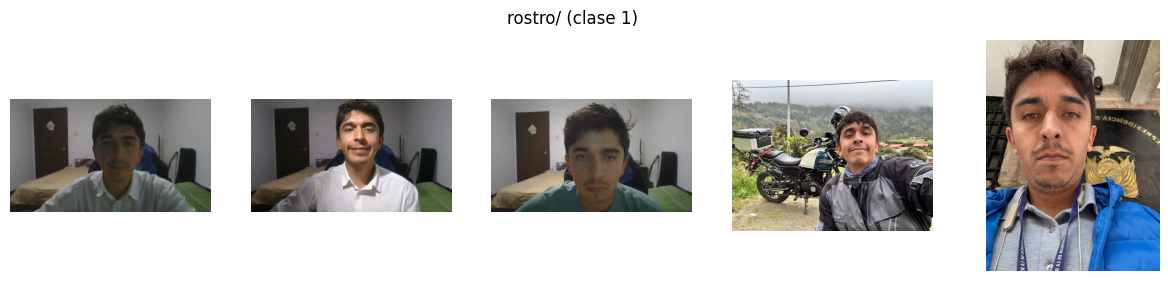

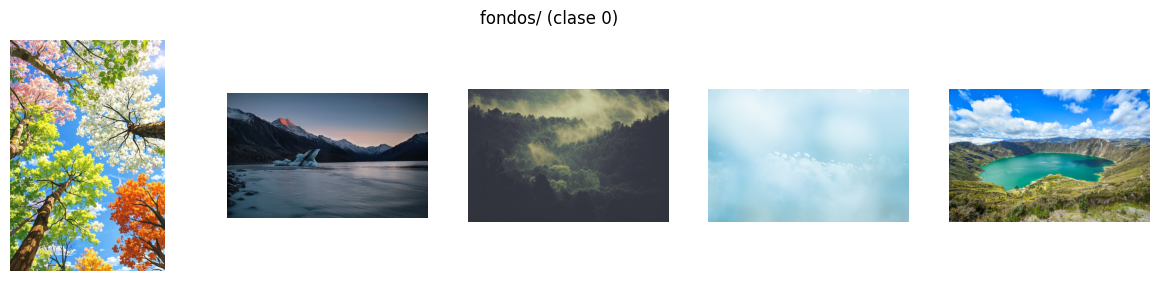

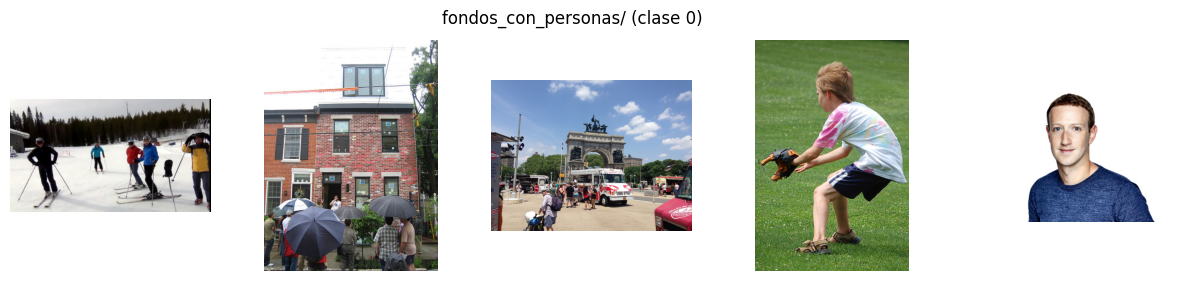

In [21]:
# Vistazo rápido: 5 imágenes de cada carpeta
def mostrar_muestra(rutas, titulo, n=5):
    fig, ejes = plt.subplots(1, n, figsize=(15, 3))
    idx = np.linspace(0, len(rutas) - 1, n).astype(int)
    for eje, i in zip(ejes, idx):
        img = cv2.imread(rutas[i])
        eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV lee en BGR; Matplotlib espera RGB
        eje.axis("off")
    fig.suptitle(titulo)
    plt.show()

mostrar_muestra(rutas_rostro, "rostro/ (clase 1)")
for c, r in rutas_fondo.items():
    mostrar_muestra(r, f"{c}/ (clase 0)")

## 6. Carga y preprocesamiento de las imágenes

Para cada imagen hacemos lo siguiente:

1. Leer con OpenCV.
2. Redimensionar a 224×224, que es el tamaño de entrada de VGG-16.
3. Convertir de BGR a RGB, porque OpenCV lee los colores en orden azul-verde-rojo.

Después aplicamos `preprocess_input` de VGG-16. Esta función centra los colores restando el promedio de las imágenes de ImageNet.

In [5]:
def preparar_imagen(img_bgr):
    # Tamaño 224x224 + RGB. Devuelve un arreglo (224, 224, 3)
    img = cv2.resize(img_bgr, (TAM, TAM))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def cargar_carpeta(rutas, etiqueta):
    imagenes, etiquetas = [], []
    for ruta in rutas:
        img = cv2.imread(ruta)
        if img is None:              # archivo dañado o no es imagen
            print("No se pudo leer:", ruta)
            continue
        imagenes.append(preparar_imagen(img))
        etiquetas.append(etiqueta)
    return imagenes, etiquetas

img_1, lab_1 = cargar_carpeta(rutas_rostro, 1)
img_0, lab_0 = [], []
for c in CARPETAS_FONDO:
    i, l = cargar_carpeta(rutas_fondo[c], 0)
    img_0 += i; lab_0 += l

images = np.array(img_1 + img_0, dtype="float32")
labels = np.array(lab_1 + lab_0)
print("Forma del tensor de imágenes:", images.shape)   # (n_imágenes, 224, 224, 3)
print("Imágenes por clase:", {CLASES[k]: int(n) for k, n in enumerate(np.bincount(labels))})

Forma del tensor de imágenes: (209, 224, 224, 3)
Imágenes por clase: {'Fondo': 97, 'Nombre del estudiante: Alexander Fernández': 112}


In [6]:
# Preprocesamiento propio de VGG-16 y one-hot encoding de las etiquetas
X = preprocess_input(images.copy())
y = to_categorical(labels, num_classes=2)   # 0 -> [1, 0] (Fondo) ; 1 -> [0, 1] (Alexander)
print("Ejemplo de etiqueta 1 en one-hot:", y[0])
print("Ejemplo de etiqueta 0 en one-hot:", y[-1])

Ejemplo de etiqueta 1 en one-hot: [0. 1.]
Ejemplo de etiqueta 0 en one-hot: [1. 0.]


## 7. División en entrenamiento y prueba

Separamos 80 % para entrenar y 20 % para validar. Usamos `stratify` para que las dos partes tengan la misma proporción de cada clase.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=labels, random_state=42)

print("Entrenamiento:", X_train.shape[0], "imágenes")
print("Prueba       :", X_test.shape[0], "imágenes")

Entrenamiento: 167 imágenes
Prueba       : 42 imágenes


## 8. Construcción del modelo: *transfer learning* con VGG-16

**Transfer learning** consiste en reutilizar una red que ya fue entrenada con millones de imágenes (ImageNet, 1 000 clases). Sus capas convolucionales ya saben detectar bordes, texturas, ojos, narices, etc. Nosotros solo entrenamos una "cabeza" pequeña que decide entre nuestras 2 clases.

La arquitectura, de entrada a salida, es:

| Bloque | Qué hace |
|---|---|
| **Aumento de datos** (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`) | En cada época crea versiones ligeramente distintas de cada foto (espejo, girada, con zoom). Así tenemos "más" datos y el modelo se vuelve más robusto. Solo actúa durante el entrenamiento. |
| **VGG-16** sin capa final (`include_top=False`), **congelada** | Extrae características de la imagen. Sus pesos no cambian. |
| `Flatten` | Convierte el mapa de características de 7×7×512 en un vector. |
| `Dense(256, relu)` | Capa oculta que aprende a combinar esas características. |
| `Dropout(0.5)` | Apaga al azar el 50 % de las neuronas en cada paso. Así evita que el modelo memorice (*overfitting*). |
| `Dense(2, softmax)` | Da 2 probabilidades que suman 1: P(Fondo) y P(Alexander). |

- Función de pérdida: `categorical_crossentropy`. Mide qué tan lejos está la probabilidad predicha de la etiqueta real (one-hot).
- Optimizador: `Adam`. Ajusta los pesos de la cabeza paso a paso.
- EarlyStopping: detiene el entrenamiento si la pérdida de validación no mejora en 5 épocas y recupera los mejores pesos.

In [8]:
# Aumento de datos (solo se activa durante el entrenamiento)
aumento = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),          # ± 18°
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
], name="aumento_de_datos")

# Red base preentrenada, sin la capa de clasificación original
baseModel = VGG16(weights="imagenet", include_top=False, input_shape=(TAM, TAM, 3))
for layer in baseModel.layers:
    layer.trainable = False               # congelamos VGG-16

model = Sequential([
    keras.Input(shape=(TAM, TAM, 3)),
    aumento,
    baseModel,
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(2, activation="softmax"),       # 2 clases: Fondo y Alexander
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,986 (80.64 MB)

 Trainable params: 6,423,298 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Casi todos los parámetros (~14,7 millones de VGG-16) son no entrenables. Solo se entrenan los ~6,4 millones de la cabeza. Por eso el entrenamiento es posible en una computadora normal y con pocas imágenes.

## 9. Entrenamiento

Ponemos un máximo de 30 épocas. `EarlyStopping` decidirá cuándo parar. En una computadora sin GPU, cada época puede tardar entre 30 segundos y 2 minutos.

Hay unas 168 imágenes de entrenamiento y batch_size=16, así que cada época son 11 pasos (168 ÷ 16 ≈ 11; por eso ves 11/11). En cada paso, el modelo ve 16 imágenes, compara sus predicciones con las etiquetas reales y ajusta un poco sus pesos. Al terminar los 11 pasos, termina una época.

In [9]:
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

historia = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/30
11/11 - 60s - 5s/step - accuracy: 0.8802 - loss: 4.3988 - val_accuracy: 0.9762 - val_loss: 3.8454
Epoch 2/30
11/11 - 70s - 6s/step - accuracy: 0.9701 - loss: 1.9524 - val_accuracy: 0.9762 - val_loss: 2.9220
Epoch 3/30
11/11 - 83s - 8s/step - accuracy: 0.9880 - loss: 1.2191 - val_accuracy: 0.9762 - val_loss: 1.3289
Epoch 4/30
11/11 - 85s - 8s/step - accuracy: 0.9820 - loss: 0.3789 - val_accuracy: 0.9762 - val_loss: 3.1673
Epoch 5/30
11/11 - 82s - 7s/step - accuracy: 1.0000 - loss: 0.0036 - val_accuracy: 0.9762 - val_loss: 1.0271
Epoch 6/30
11/11 - 78s - 7s/step - accuracy: 0.9940 - loss: 0.0733 - val_accuracy: 0.9762 - val_loss: 1.6483
Epoch 7/30
11/11 - 85s - 8s/step - accuracy: 0.9820 - loss: 0.7627 - val_accuracy: 0.9762 - val_loss: 1.2057
Epoch 8/30
11/11 - 129s - 12s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.9762 - val_loss: 0.4714
Epoch 9/30
11/11 - 77s - 7s/step - accuracy: 0.9940 - loss: 0.3355 - val_accuracy: 0.9762 - val_loss: 0.0324
Epoch 10/30
1

## 10. Evaluación en el conjunto de prueba

Loss: 0.0000
Accuracy: 1.0000

              precision    recall  f1-score   support

       Fondo      1.000     1.000     1.000        19
   Alexander      1.000     1.000     1.000        23

    accuracy                          1.000        42
   macro avg      1.000     1.000     1.000        42
weighted avg      1.000     1.000     1.000        42



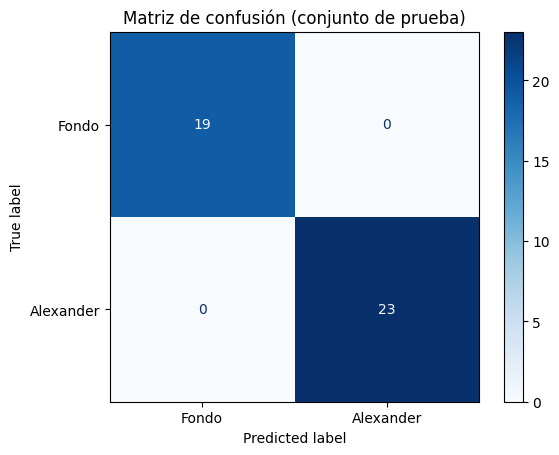

In [13]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
y_real = y_test.argmax(axis=1)
nombres_cortos = ["Fondo", "Alexander"]

print()
print(classification_report(y_real, y_pred, target_names=nombres_cortos, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred), display_labels=nombres_cortos).plot(cmap="Blues")
plt.title("Matriz de confusión (conjunto de prueba)")
plt.show()

## 11. Guardar y cargar el modelo

Guardamos en el formato nativo de Keras (`.keras`). El formato `.h5` del notebook de clase ya está marcado como *legacy* (obsoleto). Este archivo es el que usará la app de **Streamlit**.

In [14]:
model.save("modelo_alexander_vs_fondo.keras")
model = load_model("modelo_alexander_vs_fondo.keras")
print("Modelo guardado y cargado correctamente")

Modelo guardado y cargado correctamente


## 12. Función de predicción para una imagen nueva

- `pred[0][0]` → probabilidad de **Fondo**
- `pred[0][1]` → probabilidad de **Alexander**

In [22]:
def predecir(ruta, mostrar=True):
    img = cv2.imread(ruta)
    if img is None:
        raise FileNotFoundError(f"No se encontró la imagen: {ruta}")

    entrada = preprocess_input(preparar_imagen(img).astype("float32"))
    entrada = np.expand_dims(entrada, axis=0)              # (1, 224, 224, 3)
    pred = model.predict(entrada, verbose=0)

    clase = int(np.argmax(pred[0]))
    etiqueta, prob = CLASES[clase], float(pred[0][clase])

    if mostrar:
        plt.figure(figsize=(5, 5))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"{etiqueta}\n(probabilidad {prob:.1%})")
        plt.axis("off"); plt.show()
    return etiqueta, prob, pred[0]

## 13. Las 3 pruebas de la actividad

Prueba 1: test_rostro_alex.jpg


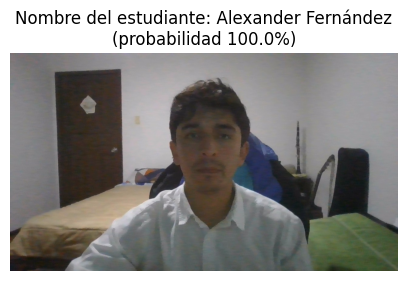

Prueba 2: test_fondo.jpg


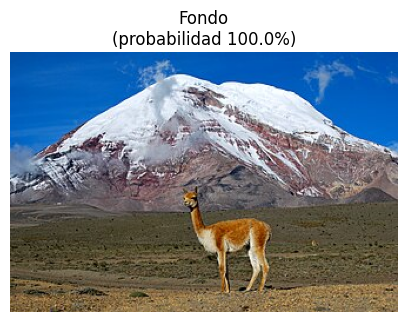

Prueba 3: test_rosto_famoso.jpg


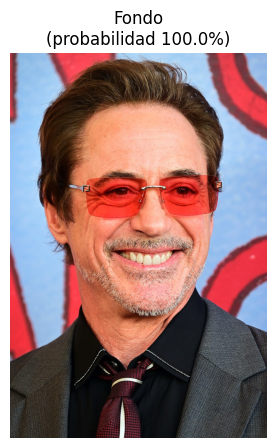

,Imagen,Etiqueta esperada,Etiqueta obtenida,P(Fondo),P(Alexander),¿Correcta?
Prueba,,,,,,
1,test_rostro_alex.jpg,Nombre del estudiante: Alexander Fernández,Nombre del estudiante: Alexander Fernández,0.000,1.000,✅
2,test_fondo.jpg,Fondo,Fondo,1.000,0.000,✅
3,test_rosto_famoso.jpg,Fondo,Fondo,1.000,0.000,✅


In [23]:
resultados = []
for i, (ruta, esperada) in enumerate(PRUEBAS, start=1):
    print(f"Prueba {i}: {ruta}")
    obtenida, prob, p = predecir(ruta)
    resultados.append({
        "Prueba": i,
        "Imagen": ruta,
        "Etiqueta esperada": esperada,
        "Etiqueta obtenida": obtenida,
        "P(Fondo)": f"{p[0]:.3f}",
        "P(Alexander)": f"{p[1]:.3f}",
        "¿Correcta?": "✅" if obtenida == esperada else "❌",
    })

tabla = pd.DataFrame(resultados).set_index("Prueba")
tabla

In [25]:
import sys; print(sys.executable)

c:\Users\pauls\AppData\Local\Programs\Python\Python313\python.exe


Note:    

cd C:\Users\pauls\Desktop\Yachay\3_Fundamentos_ia\13clase

& "C:\Users\pauls\AppData\Local\Programs\Python\Python313\python.exe" -m streamlit run app.py